# Technical Analysis with Python - an Introduction

## Installing and importing required Libraries/Packages

Install yfinance, plotly and cufflinks with:
- pip install yfinance
- pip install cufflinks

If you already have installed yfinance, please upgrade with

pip install yfinance --upgrade

__Required Action__: cufflinks is __incompatible with Numpy version 2.x__. In case you have installed Numpy 2.x please __downgrade__ with:

conda install numpy==1.26.4

__Recommendation__: matplotlib 3.8 may be more stable in conjunction with cufflinks than matplotlib 3.9. You may downgrade with: 

conda install matplotlib==3.8

__Recommendation__: pandas 1.x may be more stable in conjunction with cufflinks than pandas 2.x. You may downgrade with: 

conda install pandas==1.5.3

In [1]:
#%pip install yfinance

In [2]:
#%pip install cufflinks

In [3]:
#%!pip install --upgrade cufflinks

## Loading Financial Data from the Web

In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')

%config InlineBackened.format_figure = "retina"

In [3]:
import datetime as dt
import cufflinks as cf
import yfinance as yf

In [4]:
import warnings
warnings.filterwarnings('ignore') # ignoring FutureWarnings (Pandas >= 2.x)

-------------------------------------

__Please check your installed numpy version__:

In [5]:
np.__version__ # cufflinks won´t work with numpy 2.x (see above)

'1.26.4'

__Please check your installed matplotlib version__:

In [6]:
import matplotlib # cufflinks tends to be more stable with matplotlib 3.8 (optional)
matplotlib.__version__

'3.8.0'

__Please check your installed pandas version__:

In [7]:
pd.__version__ # 1.x works best with cufflinks

'1.5.3'

----------------------------------

In [8]:
start = "2010-01-01"
end = dt.date.today()

In [9]:
symbol = ["MSFT", "GE" , "AAPL"]

In [10]:
df = yf.download(tickers = symbol, 
                 start = start, 
                 end = end, 
                 multi_level_index = False )
df

[*********************100%***********************]  3 of 3 completed


Price            Close                                High              \
Ticker            AAPL          GE        MSFT        AAPL          GE   
Date                                                                     
2010-01-04    6.400959   53.376972   22.984240    6.415615   54.033386   
2010-01-05    6.412025   53.653366   22.991667    6.448216   54.137043   
2010-01-06    6.310037   53.376972   22.850561    6.437452   53.964290   
2010-01-07    6.298370   56.140842   22.612926    6.340842   56.935454   
2010-01-08    6.340243   57.349998   22.768875    6.340842   57.660933   
...                ...         ...         ...         ...         ...   
2026-10-07  336.670013  303.619995  529.760010  338.670013  308.549988   
2026-10-08  340.420013  305.619995  522.609985  341.570007  306.559998   
2026-10-09  336.640015  308.200012  535.070007  338.609985  308.609985   
2026-10-12  340.970001  308.640015  541.150024  342.630005  311.730011   
2026-10-13  341.269989  307.630005  543.450012  348.149994  309.980011   

Price                          Low                                Open  \
Ticker            MSFT        AAPL          GE        MSFT        AAPL   
Date                                                                     
2010-01-04   23.095633    6.352206   52.340522   22.716894    6.383611   
2010-01-05   23.095635    6.378227   53.376982   22.754027    6.418606   
2010-01-06   23.080774    6.303456   53.342421   22.664905    6.412028   
2010-01-07   22.798583    6.252608   53.307892   22.419844    6.333365   
2010-01-08   22.932252    6.252908   56.209908   22.456973    6.289995   
...                ...         ...         ...         ...         ...   
2026-10-07  531.729980  332.779999  302.980011  524.690002  336.959991   
2026-10-08  533.510010  335.899994  296.609985  518.789978  336.820007   
2026-10-09  537.219971  330.700012  303.519989  526.239990  331.700012   
2026-10-12  542.739990  337.600006  307.649994  535.700012  338.220001   
2026-10-13  551.150024  340.739990  305.200012  543.059998  344.670013   

Price                                  Volume                      
Ticker              GE        MSFT       AAPL        GE      MSFT  
Date                                                               
2010-01-04   52.582361   22.739173  493729600  13997032  38409100  
2010-01-05   53.411528   22.909979  601904800  13469263  49749600  
2010-01-06   53.653356   22.932249  552160000  11573422  58182400  
2010-01-07   53.480629   22.746598  477131200  38701038  50559700  
2010-01-08   56.348105   22.486678  447610800  24019636  51197400  
...                ...         ...        ...       ...       ...  
2026-10-07  305.510010  530.729980   34147900   3914500  16790200  
2026-10-08  299.980011  529.809998   35332400   6387500  20228700  
2026-10-09  306.290009  528.239990   37881200   2949700  18500600  
2026-10-12  307.779999  537.530029   25900600   2432300  18314900  
2026-10-13  308.000000  544.640015   38946900   4516600  23824500  

[4220 rows x 15 columns]

In [11]:
df.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4220 entries, 2010-01-04 to 2026-10-13
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   4220 non-null   float64
 1   (Close, GE)     4220 non-null   float64
 2   (Close, MSFT)   4220 non-null   float64
 3   (High, AAPL)    4220 non-null   float64
 4   (High, GE)      4220 non-null   float64
 5   (High, MSFT)    4220 non-null   float64
 6   (Low, AAPL)     4220 non-null   float64
 7   (Low, GE)       4220 non-null   float64
 8   (Low, MSFT)     4220 non-null   float64
 9   (Open, AAPL)    4220 non-null   float64
 10  (Open, GE)      4220 non-null   float64
 11  (Open, MSFT)    4220 non-null   float64
 12  (Volume, AAPL)  4220 non-null   int64  
 13  (Volume, GE)    4220 non-null   int64  
 14  (Volume, MSFT)  4220 non-null   int64  
dtypes: float64(12), int64(3)
memory usage: 527.5 KB


In [12]:
df.to_csv("stocks.csv")

## Charting - Simple Line Charts

In [13]:
df = pd.read_csv("stocks.csv", 
                 header = [0, 1], 
                 index_col = 0, 
                 parse_dates = [0],
                 infer_datetime_format=True                
                )
df

Price            Close                                High              \
Ticker            AAPL          GE        MSFT        AAPL          GE   
Date                                                                     
2010-01-04    6.400959   53.376972   22.984240    6.415615   54.033386   
2010-01-05    6.412025   53.653366   22.991667    6.448216   54.137043   
2010-01-06    6.310037   53.376972   22.850561    6.437452   53.964290   
2010-01-07    6.298370   56.140842   22.612926    6.340842   56.935454   
2010-01-08    6.340243   57.349998   22.768875    6.340842   57.660933   
...                ...         ...         ...         ...         ...   
2026-10-07  336.670013  303.619995  529.760010  338.670013  308.549988   
2026-10-08  340.420013  305.619995  522.609985  341.570007  306.559998   
2026-10-09  336.640015  308.200012  535.070007  338.609985  308.609985   
2026-10-12  340.970001  308.640015  541.150024  342.630005  311.730011   
2026-10-13  341.269989  307.630005  543.450012  348.149994  309.980011   

Price                          Low                                Open  \
Ticker            MSFT        AAPL          GE        MSFT        AAPL   
Date                                                                     
2010-01-04   23.095633    6.352206   52.340522   22.716894    6.383611   
2010-01-05   23.095635    6.378227   53.376982   22.754027    6.418606   
2010-01-06   23.080774    6.303456   53.342421   22.664905    6.412028   
2010-01-07   22.798583    6.252608   53.307892   22.419844    6.333365   
2010-01-08   22.932252    6.252908   56.209908   22.456973    6.289995   
...                ...         ...         ...         ...         ...   
2026-10-07  531.729980  332.779999  302.980011  524.690002  336.959991   
2026-10-08  533.510010  335.899994  296.609985  518.789978  336.820007   
2026-10-09  537.219971  330.700012  303.519989  526.239990  331.700012   
2026-10-12  542.739990  337.600006  307.649994  535.700012  338.220001   
2026-10-13  551.150024  340.739990  305.200012  543.059998  344.670013   

Price                                  Volume                      
Ticker              GE        MSFT       AAPL        GE      MSFT  
Date                                                               
2010-01-04   52.582361   22.739173  493729600  13997032  38409100  
2010-01-05   53.411528   22.909979  601904800  13469263  49749600  
2010-01-06   53.653356   22.932249  552160000  11573422  58182400  
2010-01-07   53.480629   22.746598  477131200  38701038  50559700  
2010-01-08   56.348105   22.486678  447610800  24019636  51197400  
...                ...         ...        ...       ...       ...  
2026-10-07  305.510010  530.729980   34147900   3914500  16790200  
2026-10-08  299.980011  529.809998   35332400   6387500  20228700  
2026-10-09  306.290009  528.239990   37881200   2949700  18500600  
2026-10-12  307.779999  537.530029   25900600   2432300  18314900  
2026-10-13  308.000000  544.640015   38946900   4516600  23824500  

[4220 rows x 15 columns]

In [14]:
df.info(null_counts = True)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4220 entries, 2010-01-04 to 2026-10-13
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   4220 non-null   float64
 1   (Close, GE)     4220 non-null   float64
 2   (Close, MSFT)   4220 non-null   float64
 3   (High, AAPL)    4220 non-null   float64
 4   (High, GE)      4220 non-null   float64
 5   (High, MSFT)    4220 non-null   float64
 6   (Low, AAPL)     4220 non-null   float64
 7   (Low, GE)       4220 non-null   float64
 8   (Low, MSFT)     4220 non-null   float64
 9   (Open, AAPL)    4220 non-null   float64
 10  (Open, GE)      4220 non-null   float64
 11  (Open, MSFT)    4220 non-null   float64
 12  (Volume, AAPL)  4220 non-null   int64  
 13  (Volume, GE)    4220 non-null   int64  
 14  (Volume, MSFT)  4220 non-null   int64  
dtypes: float64(12), int64(3)
memory usage: 527.5 KB


In [15]:
df.info(show_counts = True)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4220 entries, 2010-01-04 to 2026-10-13
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   4220 non-null   float64
 1   (Close, GE)     4220 non-null   float64
 2   (Close, MSFT)   4220 non-null   float64
 3   (High, AAPL)    4220 non-null   float64
 4   (High, GE)      4220 non-null   float64
 5   (High, MSFT)    4220 non-null   float64
 6   (Low, AAPL)     4220 non-null   float64
 7   (Low, GE)       4220 non-null   float64
 8   (Low, MSFT)     4220 non-null   float64
 9   (Open, AAPL)    4220 non-null   float64
 10  (Open, GE)      4220 non-null   float64
 11  (Open, MSFT)    4220 non-null   float64
 12  (Volume, AAPL)  4220 non-null   int64  
 13  (Volume, GE)    4220 non-null   int64  
 14  (Volume, MSFT)  4220 non-null   int64  
dtypes: float64(12), int64(3)
memory usage: 527.5 KB


In [16]:
df.Close.GE.plot(figsize = (12,8))
plt.show()

<Figure size 1200x800 with 1 Axes>

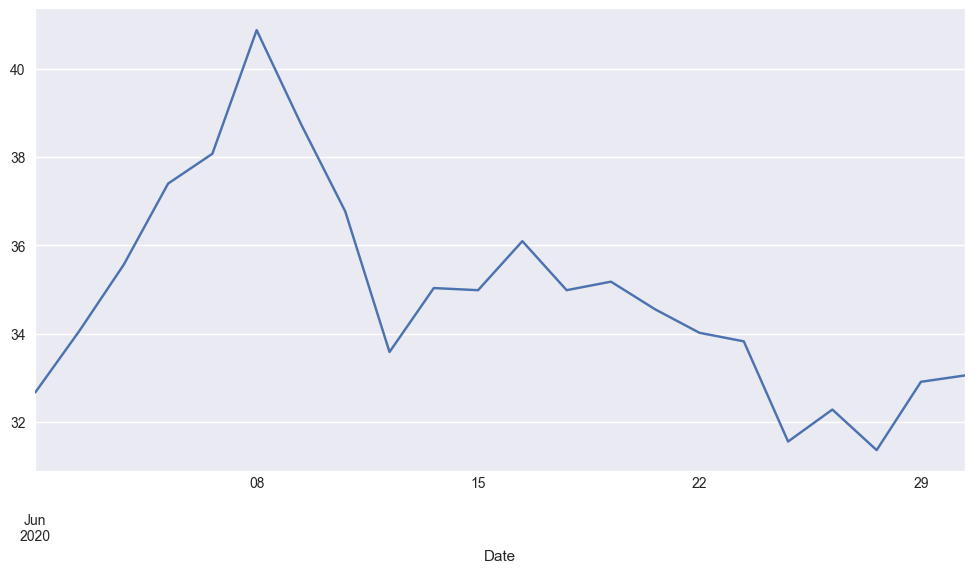

In [17]:
df.loc["2020-06" , ("Close" , "GE")].plot(figsize = (12, 6))
plt.show()

In [18]:
# df.columns = df.columns.to_flat_index()
# df.columns = pd.MultiIndex.from_tuples(df.columns)
# df.columns

In [19]:
# df = df.Close.copy()
# df

## Charting - Interactive Line Charts with Cufflinks and Plotly

In [20]:
df

Price            Close                                High              \
Ticker            AAPL          GE        MSFT        AAPL          GE   
Date                                                                     
2010-01-04    6.400959   53.376972   22.984240    6.415615   54.033386   
2010-01-05    6.412025   53.653366   22.991667    6.448216   54.137043   
2010-01-06    6.310037   53.376972   22.850561    6.437452   53.964290   
2010-01-07    6.298370   56.140842   22.612926    6.340842   56.935454   
2010-01-08    6.340243   57.349998   22.768875    6.340842   57.660933   
...                ...         ...         ...         ...         ...   
2026-10-07  336.670013  303.619995  529.760010  338.670013  308.549988   
2026-10-08  340.420013  305.619995  522.609985  341.570007  306.559998   
2026-10-09  336.640015  308.200012  535.070007  338.609985  308.609985   
2026-10-12  340.970001  308.640015  541.150024  342.630005  311.730011   
2026-10-13  341.269989  307.630005  543.450012  348.149994  309.980011   

Price                          Low                                Open  \
Ticker            MSFT        AAPL          GE        MSFT        AAPL   
Date                                                                     
2010-01-04   23.095633    6.352206   52.340522   22.716894    6.383611   
2010-01-05   23.095635    6.378227   53.376982   22.754027    6.418606   
2010-01-06   23.080774    6.303456   53.342421   22.664905    6.412028   
2010-01-07   22.798583    6.252608   53.307892   22.419844    6.333365   
2010-01-08   22.932252    6.252908   56.209908   22.456973    6.289995   
...                ...         ...         ...         ...         ...   
2026-10-07  531.729980  332.779999  302.980011  524.690002  336.959991   
2026-10-08  533.510010  335.899994  296.609985  518.789978  336.820007   
2026-10-09  537.219971  330.700012  303.519989  526.239990  331.700012   
2026-10-12  542.739990  337.600006  307.649994  535.700012  338.220001   
2026-10-13  551.150024  340.739990  305.200012  543.059998  344.670013   

Price                                  Volume                      
Ticker              GE        MSFT       AAPL        GE      MSFT  
Date                                                               
2010-01-04   52.582361   22.739173  493729600  13997032  38409100  
2010-01-05   53.411528   22.909979  601904800  13469263  49749600  
2010-01-06   53.653356   22.932249  552160000  11573422  58182400  
2010-01-07   53.480629   22.746598  477131200  38701038  50559700  
2010-01-08   56.348105   22.486678  447610800  24019636  51197400  
...                ...         ...        ...       ...       ...  
2026-10-07  305.510010  530.729980   34147900   3914500  16790200  
2026-10-08  299.980011  529.809998   35332400   6387500  20228700  
2026-10-09  306.290009  528.239990   37881200   2949700  18500600  
2026-10-12  307.779999  537.530029   25900600   2432300  18314900  
2026-10-13  308.000000  544.640015   38946900   4516600  23824500  

[4220 rows x 15 columns]

In [21]:
#pip install plotly==4.14.3

In [22]:
cf.set_config_file(offline = True)

In [23]:
cf.__version__

'0.17.3'

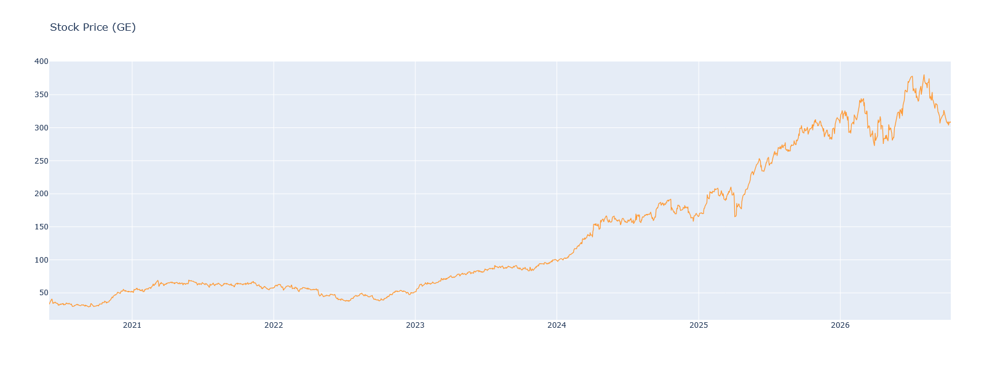

In [24]:
df.loc["2020-06": , ("Close" , "GE")].iplot(layout = {"width":1000, "height":600, "title":"Stock Price (GE)"})

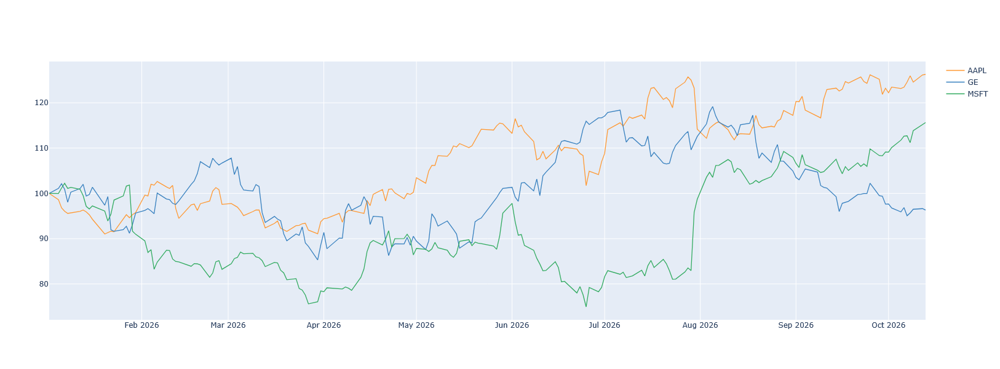

In [25]:
df.Close.loc["2026"].div(df.Close.loc["2026"].iloc[0]).mul(100).iplot(layout = {"width":1000, 
                                                                                "height":600,
                                                                                "hovermode":"x"
                                                                               })

In [26]:
df_balanced = (df / df.iloc[0])*100

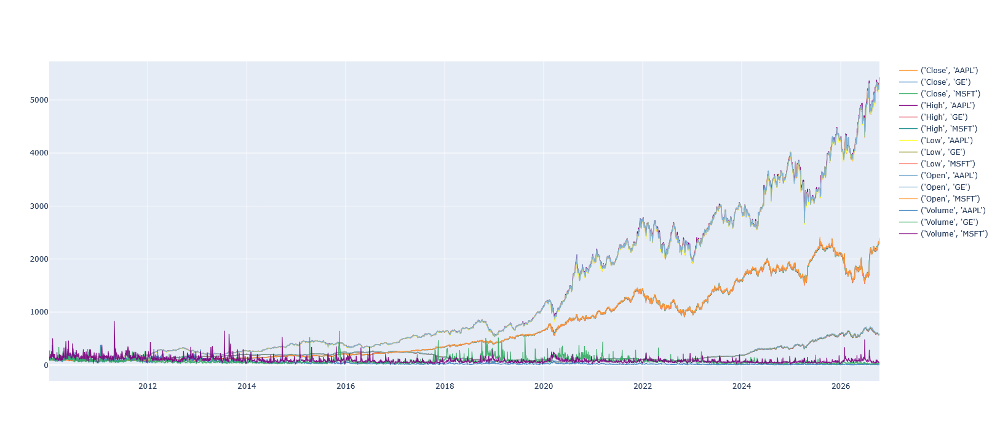

In [27]:
df_balanced.iplot(
    xTitle='Date',
    yTitle='Close Price',
    layout=dict(
       #xaxis=dict(title=dict(text='Date', font=dict(size=14))),
       #yaxis=dict(title=dict(text='Close Price', font=dict(size=14))),
       width = 1000,
       height = 700,
       hovermode = 'x'
   )
)

## Excursus: Creating Interactive Charts with Python Scripts / in a Shell

In [28]:
import pandas as pd
import numpy as np

In [29]:
import matplotlib.pyplot as plt

In [30]:
import cufflinks as cf

In [31]:
import plotly
from plotly.offline import plot

In [32]:
import yfinance as yf

In [33]:
import warnings
warnings.filterwarnings('ignore')

In [34]:
# insert full file path of our stocks.csv file
#df = pd.read_csv(r"stocks.csv", header =[0, 1], index_col = 0, parse_dates = [0])

In [35]:
cf.set_config_file(offline = True)

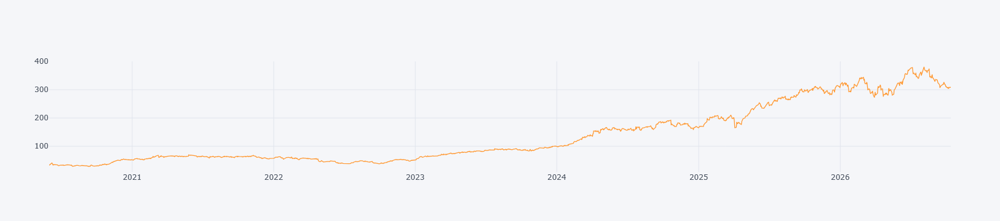

In [36]:
fig = df.loc["2020-06":,("Close","GE")].iplot(asFigure=False)

In [37]:
fig = df.loc["2020-06":,("Close","GE")].iplot(asFigure=True)

In [38]:
plot(fig)

'temp-plot.html'

In [39]:
# Select the specific column and reset the index
#data = df.loc["2020-06":, ("Close", "GE")].reset_index()
# Rename columns to simple names PX can understand
#data.columns = ["Date", "Price"]

In [40]:
#data

In [41]:
# import plotly.express as px

# fig = px.line(
#     data,
#     x="Date",
#     y="Price",
#     title="GE Closing Prices"
# )

# fig.show()

In [42]:
#pip install plotly==6.2.0

## Customizing Plotly Charts

In [43]:
df.Close

Ticker,AAPL,GE,MSFT
Date,,,
2010-01-04,6.400959,53.376972,22.984240
2010-01-05,6.412025,53.653366,22.991667
2010-01-06,6.310037,53.376972,22.850561
2010-01-07,6.298370,56.140842,22.612926
2010-01-08,6.340243,57.349998,22.768875
...,...,...,...
2026-10-07,336.670013,303.619995,529.760010
2026-10-08,340.420013,305.619995,522.609985
2026-10-09,336.640015,308.200012,535.070007


In [44]:
cf.colors.cnames

{'aliceblue': '#F0F8FF',
 'antiquewhite': '#FAEBD7',
 'aqua': '#00FFFF',
 'aquamarine': '#7FFFD4',
 'azure': '#F0FFFF',
 'beige': '#F5F5DC',
 'bisque': '#FFE4C4',
 'black': '#000000',
 'blanchedalmond': '#FFEBCD',
 'blue': '#3780bf',
 'bluegray': '#565656',
 'bluepurple': '#6432AB',
 'blueviolet': '#8A2BE2',
 'brick': '#E24A33',
 'brightblue': '#0000FF',
 'brightred': '#FF0000',
 'brown': '#A52A2A',
 'burlywood': '#DEB887',
 'cadetblue': '#5F9EA0',
 'charcoal': '#151516',
 'chartreuse': '#7FFF00',
 'chocolate': '#D2691E',
 'coral': '#FF7F50',
 'cornflowerblue': '#6495ED',
 'cornsilk': '#FFF8DC',
 'crimson': '#DC143C',
 'cyan': '#00FFFF',
 'darkblue': '#00008B',
 'darkcyan': '#008B8B',
 'darkgoldenrod': '#B8860B',
 'darkgray': '#A9A9A9',
 'darkgreen': '#006400',
 'darkgrey': '#A9A9A9',
 'darkkhaki': '#BDB76B',
 'darkmagenta': '#8B008B',
 'darkolivegreen': '#556B2F',
 'darkorange': '#FF8C00',
 'darkorchid': '#9932CC',
 'darkred': '#8B0000',
 'darksalmon': '#E9967A',
 'darkseagreen': '#8F

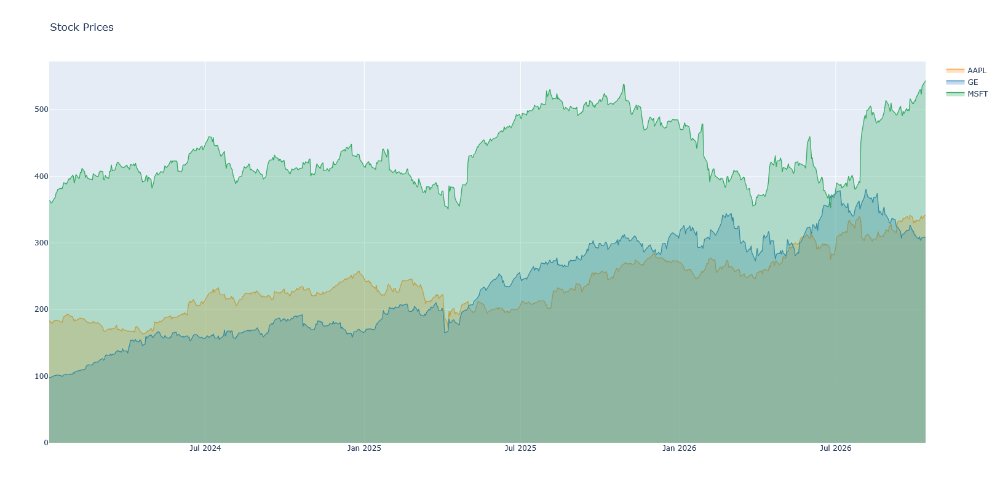

In [45]:
df.Close.loc["2024":,:].iplot(fill = True ,
                             layout = {"width":1000 , 
                                       "height":800,
                                       "title":"Stock Prices"
                                       }
                             )

In [46]:
# df.Close.reset_index()

In [47]:
# data = df.Close.reset_index()
# data

In [48]:
# fig.update_layout(
#     title="GE Closing Prices (June 2020 - Present)",
#     title_font_size=24,
#     xaxis_title="Date",
#     yaxis_title="Price (USD)",
#     xaxis=dict(showgrid=True, gridcolor="LightGray"),
#     yaxis=dict(showgrid=True, gridcolor="LightGray"),
#     plot_bgcolor="white",  # background of plot
#     paper_bgcolor="LightYellow",  # background outside plot
#     font=dict(family="Arial", size=14, color="black")
# )


In [49]:
# import plotly.express as px

# fig = px.line(
#     data,
#     x="Date",
#     y=data.columns.to_list(),
#     title="Stocks Closing Prices"
# )
# fig.update_traces(
#     hovertemplate="Date: %{x}<br>Price: $%{y:.2f}<extra></extra>"
# )
# fig.update_layout(title = "Stocks Prices Historical Charts" ,
#                   title_font_size = 24,
#                   width = 1000 , 
#                   height = 600,
#                   hovermode = 'x'# 'x' shows all y values at the same x
#                       )

# fig.show()

In [50]:
import cufflinks

In [51]:
cf.set_config_file(offline = True, sharing = True)

In [52]:
cf.colors.scales()

In [53]:
cf.getThemes()

['ggplot', 'pearl', 'solar', 'space', 'white', 'polar', 'henanigans']

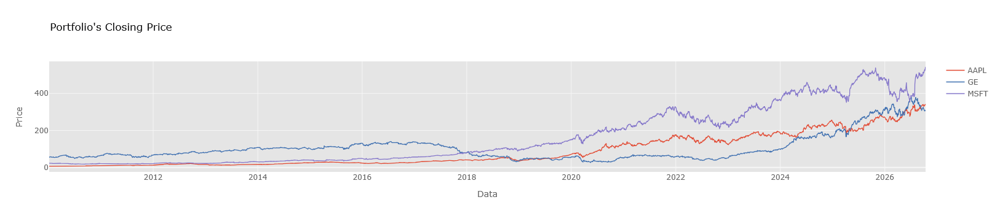

In [54]:
df.Close.iplot(fill = False , 
               theme = "ggplot" , 
               asFrame = True ,
               title = "Portfolio's Closing Price" , 
               xTitle = "Data" , 
               yTitle = "Price")

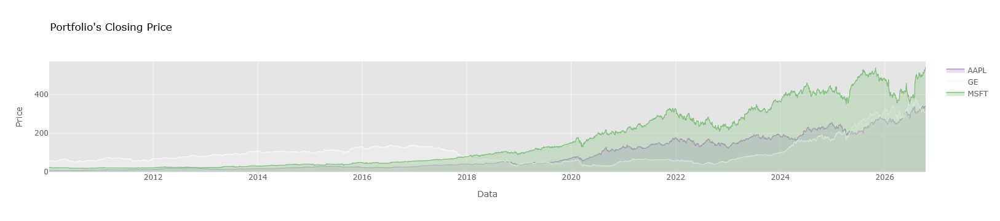

In [55]:
df.Close.iplot(fill = True , 
               theme = "ggplot" , 
               asFrame = True,
               colorscale = "prgn",
               title = "Portfolio's Closing Price" , 
               xTitle = "Data" , 
               yTitle = "Price")

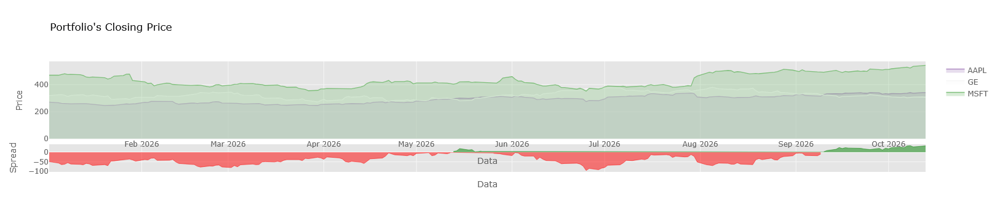

In [56]:
df.Close.loc["2026"].iplot(kind ="spread",
                           fill = True , 
                           theme = "ggplot" , 
                           asFrame = True,
                           colorscale = "prgn",
                           title = "Portfolio's Closing Price" , 
                           xTitle = "Data" , 
                           yTitle = "Price",
                          )

In [57]:
df.Close.loc[:,["AAPL"]]

Ticker,AAPL
Date,
2010-01-04,6.400959
2010-01-05,6.412025
2010-01-06,6.310037
2010-01-07,6.298370
2010-01-08,6.340243
...,...
2026-10-07,336.670013
2026-10-08,340.420013
2026-10-09,336.640015


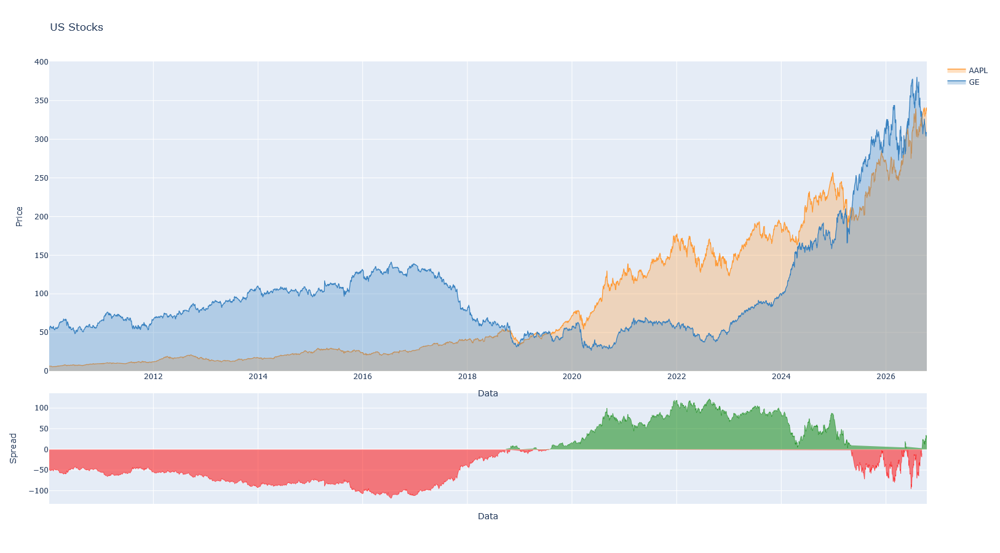

In [58]:
df.Close.loc[: , ["AAPL","GE"]].iplot(fill = True, 
         kind ="spread",
         layout = {
        'title': 'US Stocks',
        'xaxis': {'title': 'Data'},
        'yaxis': {'title': 'Price'},
        'width': 1400,
        'height': 900,
        'showlegend': True,
        #'paper_bgcolor': 'lightgray',
        #'plot_bgcolor': 'white',
        'hovermode':'x'
        })

In [59]:
df_balanced = df.Close.loc[: , ["AAPL","GE"]].div(df.Close.loc[: , ["AAPL","GE"]].iloc[0]).mul(100)
df_balanced

Ticker,AAPL,GE
Date,,
2010-01-04,100.000000,100.000000
2010-01-05,100.172887,100.517815
2010-01-06,98.579551,100.000000
2010-01-07,98.397285,105.178020
2010-01-08,99.051460,107.443334
...,...,...
2026-10-07,5259.680817,568.822064
2026-10-08,5318.265789,572.568998
2026-10-09,5259.212157,577.402576


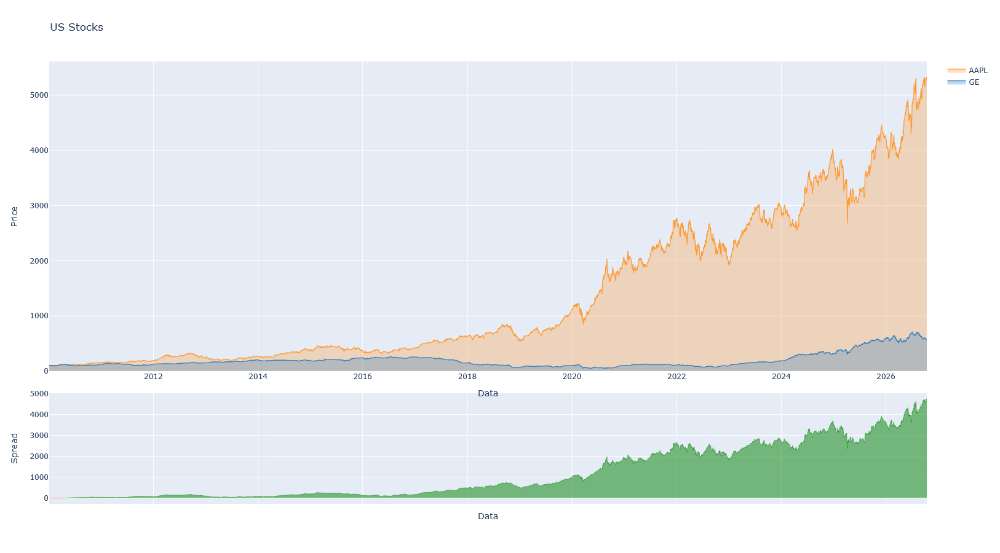

In [60]:
df_balanced.iplot(fill = True, 
         kind ="spread",
         layout = {
        'title': 'US Stocks',
        'xaxis': {'title': 'Data'},
        'yaxis': {'title': 'Price'},
        'width': 1400,
        'height': 900,
        'showlegend': True,
        #'paper_bgcolor': 'lightgray',
        #'plot_bgcolor': 'white',
        'hovermode':'x'
        })

In [61]:
cf.colors.cnames

{'aliceblue': '#F0F8FF',
 'antiquewhite': '#FAEBD7',
 'aqua': '#00FFFF',
 'aquamarine': '#7FFFD4',
 'azure': '#F0FFFF',
 'beige': '#F5F5DC',
 'bisque': '#FFE4C4',
 'black': '#000000',
 'blanchedalmond': '#FFEBCD',
 'blue': '#3780bf',
 'bluegray': '#565656',
 'bluepurple': '#6432AB',
 'blueviolet': '#8A2BE2',
 'brick': '#E24A33',
 'brightblue': '#0000FF',
 'brightred': '#FF0000',
 'brown': '#A52A2A',
 'burlywood': '#DEB887',
 'cadetblue': '#5F9EA0',
 'charcoal': '#151516',
 'chartreuse': '#7FFF00',
 'chocolate': '#D2691E',
 'coral': '#FF7F50',
 'cornflowerblue': '#6495ED',
 'cornsilk': '#FFF8DC',
 'crimson': '#DC143C',
 'cyan': '#00FFFF',
 'darkblue': '#00008B',
 'darkcyan': '#008B8B',
 'darkgoldenrod': '#B8860B',
 'darkgray': '#A9A9A9',
 'darkgreen': '#006400',
 'darkgrey': '#A9A9A9',
 'darkkhaki': '#BDB76B',
 'darkmagenta': '#8B008B',
 'darkolivegreen': '#556B2F',
 'darkorange': '#FF8C00',
 'darkorchid': '#9932CC',
 'darkred': '#8B0000',
 'darksalmon': '#E9967A',
 'darkseagreen': '#8F

In [62]:
cf.colors.scales()

In [63]:
cf.getThemes()

['ggplot', 'pearl', 'solar', 'space', 'white', 'polar', 'henanigans']